In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split,KFold,cross_val_score
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,make_scorer,accuracy_score

import numpy as np

In [3]:
concrete=pd.read_csv('concrete.csv')
concrete.head()


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
concrete.info()


<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cement        1030 non-null   float64
 1   slag          1030 non-null   float64
 2   ash           1030 non-null   float64
 3   water         1030 non-null   float64
 4   superplastic  1030 non-null   float64
 5   coarseagg     1030 non-null   float64
 6   fineagg       1030 non-null   float64
 7   age           1030 non-null   int64  
 8   strength      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


concrete.isna().sum()

In [5]:
concrete.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [6]:
concrete.shape

(1030, 9)

## EDA Analysis

### correlation heat map

In [7]:
correlation=concrete.corr()
correlation

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
cement,1.000000,-0.275216,-0.397467,-0.081587,0.092386,-0.109349,-0.222718,0.081946,0.497832
slag,-0.275216,1.000000,-0.323580,0.107252,0.043270,-0.283999,-0.281603,-0.044246,0.134829
ash,-0.397467,-0.323580,1.000000,-0.256984,0.377503,-0.009961,0.079108,-0.154371,-0.105755
water,-0.081587,0.107252,-0.256984,1.000000,-0.657533,-0.182294,-0.450661,0.277618,-0.289633
superplastic,0.092386,0.043270,0.377503,-0.657533,1.000000,-0.265999,0.222691,-0.192700,0.366079
coarseagg,-0.109349,-0.283999,-0.009961,-0.182294,-0.265999,1.000000,-0.178481,-0.003016,-0.164935
fineagg,-0.222718,-0.281603,0.079108,-0.450661,0.222691,-0.178481,1.000000,-0.156095,-0.167241
age,0.081946,-0.044246,-0.154371,0.277618,-0.192700,-0.003016,-0.156095,1.000000,0.328873
strength,0.497832,0.134829,-0.105755,-0.289633,0.366079,-0.164935,-0.167241,0.328873,1.000000


<Axes: >

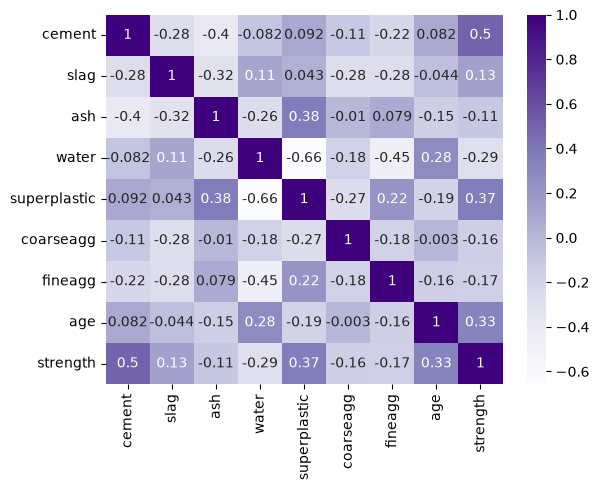

In [8]:
sns.heatmap(correlation,annot=True,cmap='Purples')

## pairplot for each columns vs strength

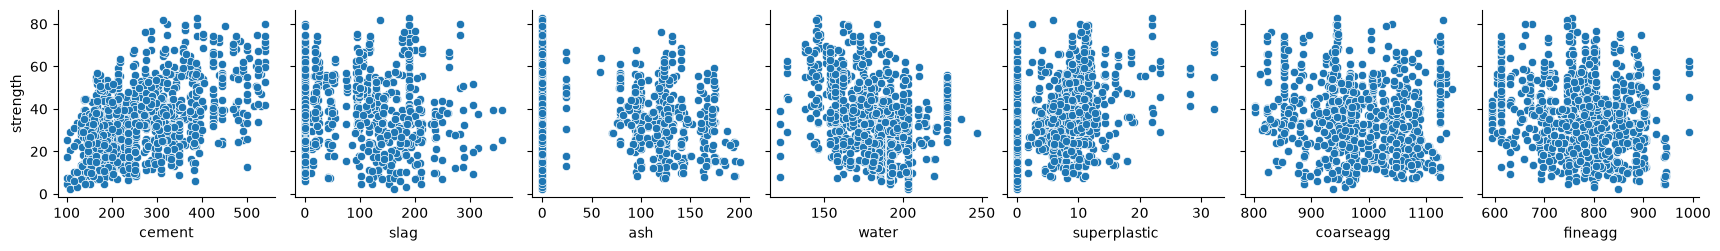

In [9]:
sns.pairplot(x_vars=['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg',
       'fineagg'],
    y_vars=['strength'],data=concrete
)

## histogram for strength distribution

<Axes: xlabel='strength', ylabel='Count'>

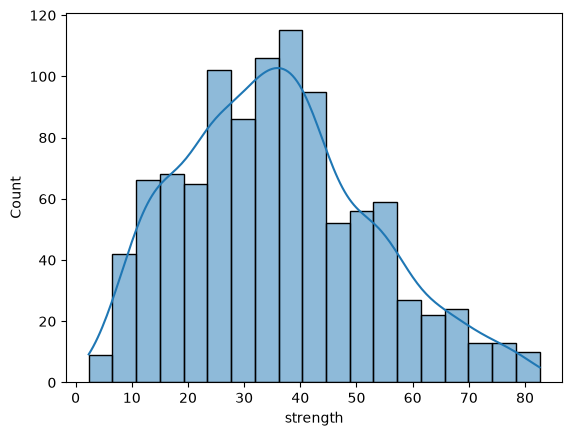

In [10]:
sns.histplot(concrete['strength'],kde=True)

# Feature Engineering

In [11]:
## add new column cement and water ratio

In [12]:
concrete['cement_water_ratio']=concrete['water']/concrete['cement']

In [13]:
concrete['cement_water_ratio']

0       0.300000
1       0.300000
2       0.685714
3       0.685714
4       0.966767
          ...   
1025    0.649783
1026    0.608318
1027    1.297643
1028    1.103708
1029    0.768877
Name: cement_water_ratio, Length: 1030, dtype: float64

In [14]:
## skewness handle

In [15]:
## chevk skewness for each column

In [16]:
check_value=[]
for i in (concrete.columns):
    check_value.append(concrete[i].skew())
    
    

In [17]:
check_value

[np.float64(0.509481178871773),
 np.float64(0.8007168956061772),
 np.float64(0.5373539058066844),
 np.float64(0.07462838428549402),
 np.float64(0.9072025748672465),
 np.float64(-0.04021974481106706),
 np.float64(-0.25300959769707576),
 np.float64(3.26917740063459),
 np.float64(0.416977288410718),
 np.float64(0.9580720869509917)]

In [18]:
skew_summary = pd.Series(check_value, index=concrete.columns)
print(skew_summary)

cement                0.509481
slag                  0.800717
ash                   0.537354
water                 0.074628
superplastic          0.907203
coarseagg            -0.040220
fineagg              -0.253010
age                   3.269177
strength              0.416977
cement_water_ratio    0.958072
dtype: float64


In [19]:
## slag,superplastic,age,cemet_water_ratio are skweness data

In [20]:
## visulaize

In [21]:
concrete.columns

Index(['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg',
       'fineagg', 'age', 'strength', 'cement_water_ratio'],
      dtype='str')

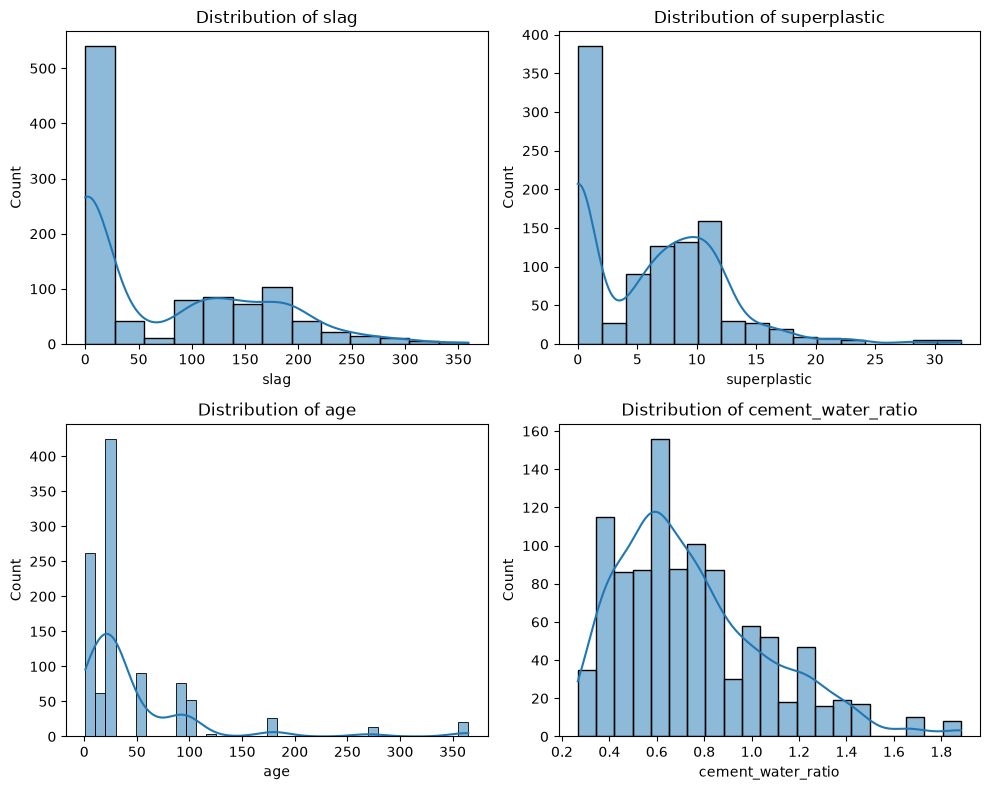

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()
# 2. Skewed columns list
skew_columns = ['slag', 'superplastic', 'age', 'cement_water_ratio']

# 3. For loop la iterate panni plot podrom
for i, name in enumerate(skew_columns):
  sns.histplot(concrete[name], ax=axes[i], kde=True)
  axes[i].set_title(f'Distribution of {name}')

plt.tight_layout()
plt.show()


In [23]:
## using powerTransformer for automatically change into the normal data

In [24]:
skew_columns = ['slag', 'superplastic', 'age', 'cement_water_ratio']
pt=PowerTransformer(method='yeo-johnson') ## handle negatice value
concrete[skew_columns]=pt.fit_transform(concrete[skew_columns])

In [25]:
## check the skewness

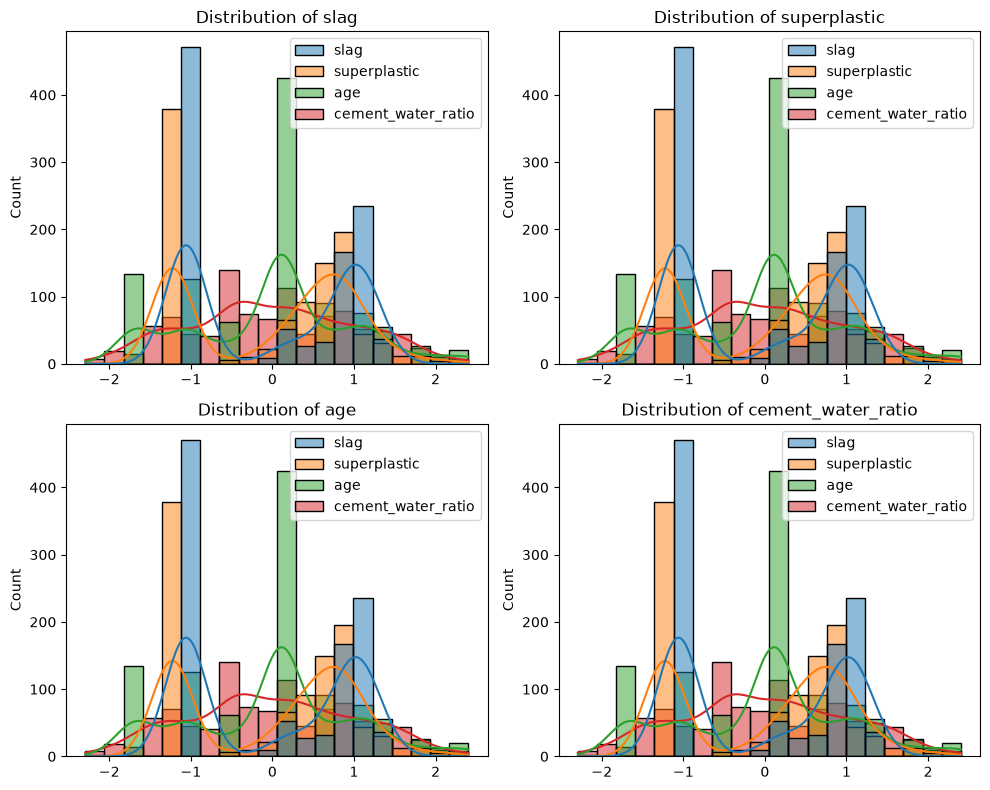

In [26]:
skew_columns = ['slag', 'superplastic', 'age', 'cement_water_ratio']
fig,axes=plt.subplots(2,2,figsize=(10, 8))
axes=axes.flatten()

for i,name in enumerate(skew_columns):
    sns.histplot(concrete[skew_columns],ax=axes[i],kde=True)

    axes[i].set_title(f'Distribution of {name}')

plt.tight_layout()
plt.show()

In [27]:
check_value=[]
for i in (concrete.columns):
    check_value.append(concrete[i].skew())
    
    

In [28]:
check_value

[np.float64(0.509481178871773),
 np.float64(-0.02504692049694679),
 np.float64(0.5373539058066844),
 np.float64(0.07462838428549402),
 np.float64(-0.16105293417241878),
 np.float64(-0.04021974481106706),
 np.float64(-0.25300959769707576),
 np.float64(-0.00023388925570981615),
 np.float64(0.416977288410718),
 np.float64(0.05748235915476918)]

 # Data Preproccessing

In [29]:
x=concrete.drop(columns='strength')
y=concrete['strength']

In [30]:
scaled=StandardScaler()


In [31]:
x_scaled=scaled.fit_transform(x)

# Feature Selection for linear regression

In [32]:
linear_model=LinearRegression()
rfe=RFE(linear_model,n_features_to_select=8)
rfe.fit(x_scaled,y)
x_selected=concrete[x.columns[rfe.get_support(indices=True)]]
x_selected

,cement,slag,ash,water,superplastic,fineagg,age,cement_water_ratio
0,540.0,-1.057530,0.0,162.0,-0.327700,676.0,0.111732,-1.964306
1,540.0,-1.057530,0.0,162.0,-0.327700,676.0,0.111732,-1.964306
2,332.5,1.001476,0.0,228.0,-1.225815,594.0,2.129725,-0.012063
3,332.5,1.001476,0.0,228.0,-1.225815,594.0,2.401693,-0.012063
4,198.6,0.969970,0.0,192.0,-1.225815,825.5,2.389241,0.852299
...,...,...,...,...,...,...,...,...
1025,276.4,0.913437,90.3,179.6,0.679902,768.3,0.111732,-0.148364
1026,322.2,-1.057530,115.6,196.0,0.839200,813.4,0.111732,-0.314778
1027,148.5,0.992044,108.6,192.7,0.327196,780.0,0.111732,1.554246
1028,159.1,1.117718,0.0,175.6,0.927490,788.9,0.111732,1.174966


# validation

In [33]:
x_train,x_test,y_train,y_test=train_test_split(x_selected,y,test_size=0.2,random_state=42)

In [34]:
kfold=KFold(n_splits=5,shuffle=True,random_state=42)

In [41]:
accuracy_score=cross_val_score(linear_model,x_selected,y,cv=kfold,scoring=make_scorer(mean_squared_error,greater_is_better=False))

In [42]:
-accuracy_score

array([46.7714497 , 72.53662188, 59.74115175, 52.21922667, 46.41183233])

In [43]:
-accuracy_score.mean()

np.float64(55.53605646521889)

In [44]:
-accuracy_score.std()

np.float64(-9.775205454994659)

# model build

In [88]:
linear_model=LinearRegression()

In [89]:
linear_model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.04, 5.5 , 0.01,...,-0.01,10.03,-4.93]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['cement','slag','ash',...,'fineagg','age','cement_water_ratio']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,57.74
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [90]:
y_pred=linear_model.predict(x_test)

# Evaluate the model

In [93]:
mae_test=mean_absolute_error(y_test,y_pred)
mae_test

5.52020531622829

In [98]:
mse=mean_squared_error(y_test,y_pred)
mse

46.77144969978256

In [99]:
rmse=np.sqrt(mse)
rmse

np.float64(6.838965543105372)

In [100]:
r2_score(y_test,y_pred)

0.8184879951485153

In [ ]:
# create model using random forest